# Optional supplement to Prelab 06: chi-squared minimization in more detail

**This notebook is optional, and is not submitted.** It has two extras for Prelab 06:

1. a visualization of how chi-squared changes as the slope moves away from its best-fit value, showing that the best fit sits at the minimum; and
2. the full derivation of the analytic formula for the best-fit slope of the one-parameter model, $y = mx$, from Section 6.4 of the prelab.

The code here is for illustration only. You will not need it in your lab notebook.

In [1]:
# Run me to import the relevant libraries

%reset -f

import numpy as np
import matplotlib.pyplot as plt
from phys119_functions import *

## 1. Visualizing chi-squared minimization

Below, you can see a visualization of how the analytically-determined $m$, found with `autofit()` as in Section 6.6 of the prelab, lies at the lowest point of the chi-squared vs. $m$ curve (as expected for a minimum). We fix $b$ as our best fit value and then use an array of many different $m$ values, with chi-squared calculated for each of these different slope values. Finally, the calculated chi-squared values are plotted versus the slope values.

The code below uses a programming construction of Python called a "for" loop. You will not need to know how to use these!

Run the cell below to load the example data from Sections 6.3 and 6.6 of the prelab, with the well-estimated uncertainties, and find its best fit.

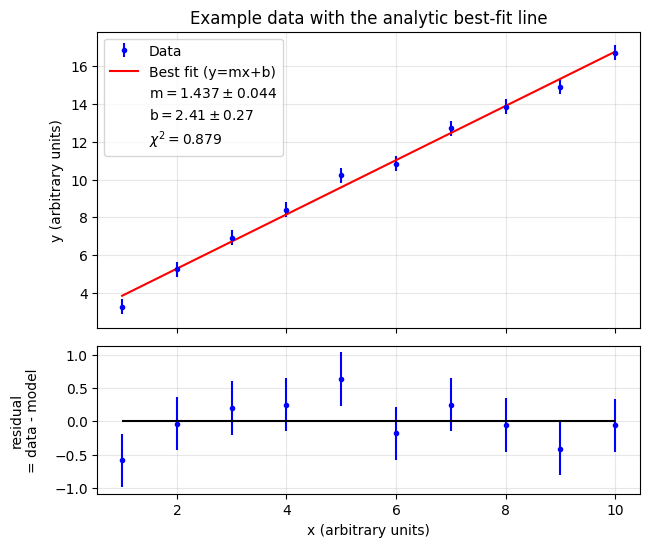

autofit1: m = 1.437 ± 0.044, b = 2.41 ± 0.27, χ² = 0.879


In [2]:
# Run me to load the example data and find its best fit

x_review = np.array([1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0])
y_review = np.array([3.26, 5.25, 6.92, 8.41, 10.23, 10.85, 12.72, 13.85, 14.93, 16.72])
dy_well_estimated = np.array([0.40, 0.40, 0.40, 0.40, 0.40, 0.40, 0.40, 0.40, 0.40, 0.40])

autofit(
    x=x_review, y=y_review, dy=dy_well_estimated,
    title="Example data with the analytic best-fit line",
    x_label="x (arbitrary units)",
    y_label="y (arbitrary units)",
    data_label="Data",
)

Now run the cell below to calculate chi-squared for 100 slopes around the best-fit value, from $m - \delta m$ to $m + \delta m$, keeping $b$ fixed at its best-fit value, and plot them.

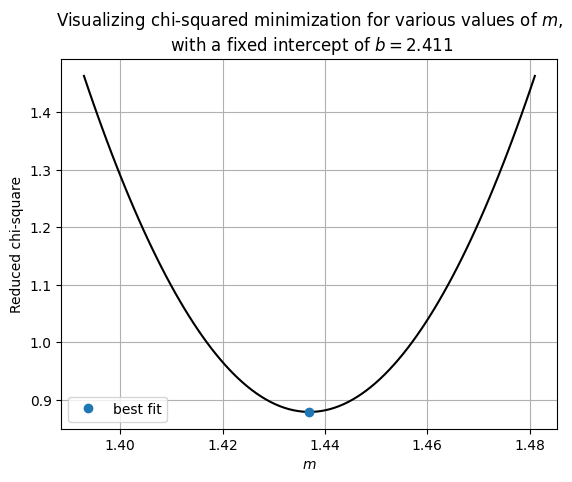

In [3]:
# Run me to see a plot of chi-squared vs slope, for slopes from m - dm to m + dm
# - This code is for information only and not intended to be used in
#   your lab notebook

x_data = x_review
y_data = y_review
del_y_data = dy_well_estimated
N = len(x_data)

# prepare an array of different slope values around the best-fit slope
mVec = np.linspace(autofit1.m - autofit1.dm, autofit1.m + autofit1.dm, 100)
# create an array of chi-squared values, set each to 0 for now
reduced_chi_squareVec = np.zeros(np.size(mVec))

for i in range(len(mVec)):  # loop through all the different m values
    # This indented code is executed once for each of the m values:
    # we calculate chi-squared for each possible slope.
    ymodelTemp = mVec[i] * x_data + autofit1.b       # model for the current value of m
    resTemp = y_data - ymodelTemp                # residuals for this model
    wres2Temp = (resTemp / del_y_data)**2        # weighting these residuals
    reduced_chi_squareVec[i] = np.sum(wres2Temp) / (N - 2)  # store chi-squared

plt.figure()
plt.plot(mVec, reduced_chi_squareVec, 'k')
plt.plot(autofit1.m, autofit1.chi2, 'o', label='best fit')
plt.xlabel('$m$')
plt.ylabel('Reduced chi-square')
plt.title(
    f'Visualizing chi-squared minimization for various values of $m$,'
    f'\n with a fixed intercept of $b =${autofit1.b:.3f}'
    )
plt.legend()
plt.grid()
plt.show()

The best-fit slope sits at the bottom of the curve: moving the slope away from it in either direction, while keeping $b$ fixed, increases chi-squared.

## 2. The full derivation of the analytic formula for minimizing chi-squared for the one-parameter model, $y = mx$

From your calculus courses, you know that you can take a continuous function $f(x)$ and find the minimum or maximum (a critical point, $x_c$) by taking the derivative of $f(x)$ with respect to $x$, setting this derivative equal to zero, and solving the resulting equation

$$\left[\frac{df(x)}{dx}\right]_{x=x_c}=0.$$

Since $\chi^2$ is a continuous function, we can do exactly this process to come up with an expression that automatically calculates the critical point(s), to find the minimum. In other words, we can use calculus to derive an *analytic* expression for the best fit parameter(s).

Wait a minute, how do we know the critical point will be a minimum and not a maximum? If we think about fitting a model to data that is finite, we know that as we move the parameters to $+\infty$ and $-\infty$ the fit will become increasingly worse to the data, meaning that chi-squared has no maxima. From this observation is follows that any critical point found must be a minimum.*

In the simplest case of a one-parameter linear model, $y=mx$, we wish to minimize chi-squared with respect to $m$ to find the best fit slope

$$ \frac{d\chi^2(m)}{dm} = 0.$$

We can first substitute our general expression for chi-squared

$$ \frac{d}{dm}\left[ \frac{1}{N-P} \sum_{i=1}^N \left(\frac{y_i - f(x_i)}{\delta y_i}\right)^2 \right] = 0.$$

Our model is $f(x_i) = mx_i$, which we can substitute into the above expression

$$ \frac{d}{dm}\left[ \frac{1}{N-P} \sum_{i=1}^N \left(\frac{y_i - mx_i}{\delta y_i}\right)^2 \right] = 0.$$

Since the derivative is with respect to $m$, it has no effect on $N$ or $P$, meaning we can move that leading fraction outside of the derivative.

$$ \frac{1}{N-P} \frac{d}{dm} \sum_{i=1}^N \left(\frac{y_i - mx_i}{\delta y_i}\right)^2 = 0.$$

The summation is only over variables with a subscript "$i$"; $m$ does not contain this so we can also switch the order of differentiation and summation

$$ \frac{1}{N-P} \sum_{i=1}^N \frac{d}{dm} \left(\frac{y_i - mx_i}{\delta y_i}\right)^2 = 0.$$

Now we perform some calculus and take the derivative (invoking the chain rule)

$$ \frac{2}{N-P} \sum_{i=1}^N  \left(\frac{y_i - mx_i}{\delta y_i}\right) \cdot \frac{d}{dm} \left(\frac{y_i - mx_i}{\delta y_i}\right)= 0,$$

$$ \frac{2}{N-P} \sum_{i=1}^N  \left(\frac{y_i - mx_i}{\delta y_i}\right) \cdot \left(-\frac{x_i}{\delta y_i}\right) = 0.$$

The negative sign can be taken outside the sum, and since we are setting everything equal to zero the $2/(N-P)$ can be discarded

$$ \sum_{i=1}^N  \left(\frac{y_i - mx_i}{\delta y_i}\right) \cdot \frac{x_i}{\delta y_i} = 0.$$

What remains is to rearrange this expression for $m$. We can start by expanding the terms in the summation

$$ \sum_{i=1}^N  \left(\frac{y_i}{\delta y_i} - m\frac{x_i}{\delta y_i}\right) \cdot \frac{x_i}{\delta y_i} = 0$$
$$ \sum_{i=1}^N  \frac{x_iy_i}{(\delta y_i)^2} - m\frac{x_i^2}{(\delta y_i)^2} = 0$$

then finally isolate $m$

$$ m = \frac{\displaystyle \sum_{i=1}^N  \frac{x_iy_i}{(\delta y_i)^2}}{\displaystyle \sum_{i=1}^N \frac{x_i^2}{(\delta y_i)^2}} $$

So given our $x$ and $y$ data plus the uncertainty in $y$, we are able to analytically solve for the best fit slope using this equation! The uncertainty in this slope can be determined from the uncertainties in the data by uncertainty propagation. The result is:

$$ \delta m = \sqrt{\frac{1}{\displaystyle \sum_{i=1}^N \frac{x_i^2}{(\delta y_i)^2}}} .$$

Since the term $\sum_{i=1}^N \frac{x_i^2}{(\delta y_i)^2}$ appears both in $m$ and $\delta m$, it is convenient for notation and coding purposes to define a placeholder variable

$$ Z = \sum_{i=1}^N \frac{x_i^2}{(\delta y_i)^2} $$

such that

$$ m = \frac{1}{Z} \sum_{i=1}^N  \frac{x_iy_i}{(\delta y_i)^2} $$
$$ \delta m = \sqrt{\frac{1}{Z}} .$$